# Hotel Booking Cancellation Prediction

This notebook is the project documentation. Every step has **code**, a **figure or table**, and a **Decision** cell that explains what we found and why we chose what we did.

| Rubric item | Section |
|---|---|
| 1. Data cleaning and preprocessing | 2, 3 |
| 2. Feature selection | 4 |
| 3. Model selection, training and testing | 5 |
| 4. Meta-classifier | 6 |
| 5. EC2 deployment and testing | 7 (saves the model) + README |

## 1. Objective
Predict whether a customer will **cancel** their hotel booking (target column: `booking status`).

- Problem type: binary classification (`Canceled` = 1, `Not_Canceled` = 0)
- Final model: a stacking **meta-classifier** built on the 3 best base models
- The final model is served by a FastAPI app on an AWS EC2 instance

In [2]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# project root = folder that contains data/, src/, models/ (works from notebooks/ or the root)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import preprocessing as pp  # same code the API uses

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", font_scale=0.95)
C_NOT, C_CAN = "#3b6fb6", "#d9622b"  # Not_Canceled = blue, Canceled = orange (used everywhere)
STATUS_PALETTE = {"Not_Canceled": C_NOT, "Canceled": C_CAN}

## 2. Dataset column details

In [3]:
df_raw = pd.read_csv(ROOT / "data/raw/booking.csv")
df = df_raw.copy()
print("rows, columns:", df.shape)
df.head()

rows, columns: (36285, 17)


,Booking_ID,number of adults,number of children,number of weekend nights,number of week nights,type of meal,car parking space,room type,lead time,market segment type,repeated,P-C,P-not-C,average price,special requests,date of reservation,booking status
0,INN00001,1,1,2,5,Meal Plan 1,0,Room_Type 1,224,Offline,0,0,0,88.00,0,10/2/2015,Not_Canceled
1,INN00002,1,0,1,3,Not Selected,0,Room_Type 1,5,Online,0,0,0,106.68,1,11/6/2018,Not_Canceled
2,INN00003,2,1,1,3,Meal Plan 1,0,Room_Type 1,1,Online,0,0,0,50.00,0,2/28/2018,Canceled
3,INN00004,1,0,0,2,Meal Plan 1,0,Room_Type 1,211,Online,0,0,0,100.00,1,5/20/2017,Canceled
4,INN00005,1,0,1,2,Not Selected,0,Room_Type 1,48,Online,0,0,0,77.00,0,4/11/2018,Canceled


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36285 entries, 0 to 36284
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Booking_ID                36285 non-null  str    
 1   number of adults          36285 non-null  int64  
 2   number of children        36285 non-null  int64  
 3   number of weekend nights  36285 non-null  int64  
 4   number of week nights     36285 non-null  int64  
 5   type of meal              36285 non-null  str    
 6   car parking space         36285 non-null  int64  
 7   room type                 36285 non-null  str    
 8   lead time                 36285 non-null  int64  
 9   market segment type       36285 non-null  str    
 10  repeated                  36285 non-null  int64  
 11  P-C                       36285 non-null  int64  
 12  P-not-C                   36285 non-null  int64  
 13  average price             36285 non-null  float64
 14  special requests 

In [5]:
# numerical or categorical? (type of each column and how we treat it)
kinds = {pp.ID_COL: "identifier", pp.DATE_COL: "date (text)", pp.TARGET: "target"}
kinds.update({c: "categorical" for c in pp.CATEGORICAL_COLS})
kinds.update({c: "binary (0/1)" for c in pp.BINARY_COLS})
kinds.update({c: "numerical" for c in pp.NUMERIC_COLS})

col_summary = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "kind": pd.Series(kinds),
        "unique values": df.nunique(),
        "first row": df.iloc[0],
    }
)
col_summary

,dtype,kind,unique values,first row
Booking_ID,str,identifier,36285,INN00001
P-C,int64,numerical,9,0
P-not-C,int64,numerical,59,0
average price,float64,numerical,3930,88.0
booking status,str,target,2,Not_Canceled
car parking space,int64,binary (0/1),2,0
date of reservation,str,date (text),553,10/2/2015
lead time,int64,numerical,352,224
market segment type,str,categorical,5,Offline
number of adults,int64,numerical,5,1


In [6]:
# summary statistics
print("Numerical columns")
display(df[pp.NUMERIC_COLS].describe().T)
print("Categorical columns")
display(df[pp.CATEGORICAL_COLS + [pp.TARGET]].describe().T)

Numerical columns


,count,mean,std,min,25%,50%,75%,max
number of adults,36285.0,1.844839,0.518813,0.0,2.0,2.00,2.0,4.0
number of children,36285.0,0.105360,0.402704,0.0,0.0,0.00,0.0,10.0
number of weekend nights,36285.0,0.810693,0.870590,0.0,0.0,1.00,2.0,7.0
number of week nights,36285.0,2.204602,1.410946,0.0,1.0,2.00,3.0,17.0
lead time,36285.0,85.239851,85.938796,0.0,17.0,57.00,126.0,443.0
P-C,36285.0,0.023343,0.368281,0.0,0.0,0.00,0.0,13.0
P-not-C,36285.0,0.153369,1.753931,0.0,0.0,0.00,0.0,58.0
average price,36285.0,103.421636,35.086469,0.0,80.3,99.45,120.0,540.0
special requests,36285.0,0.619733,0.786262,0.0,0.0,0.00,1.0,5.0


Categorical columns


,count,unique,top,freq
type of meal,36285,4,Meal Plan 1,27842
room type,36285,7,Room_Type 1,28138
market segment type,36285,5,Online,23221
booking status,36285,2,Not_Canceled,24396


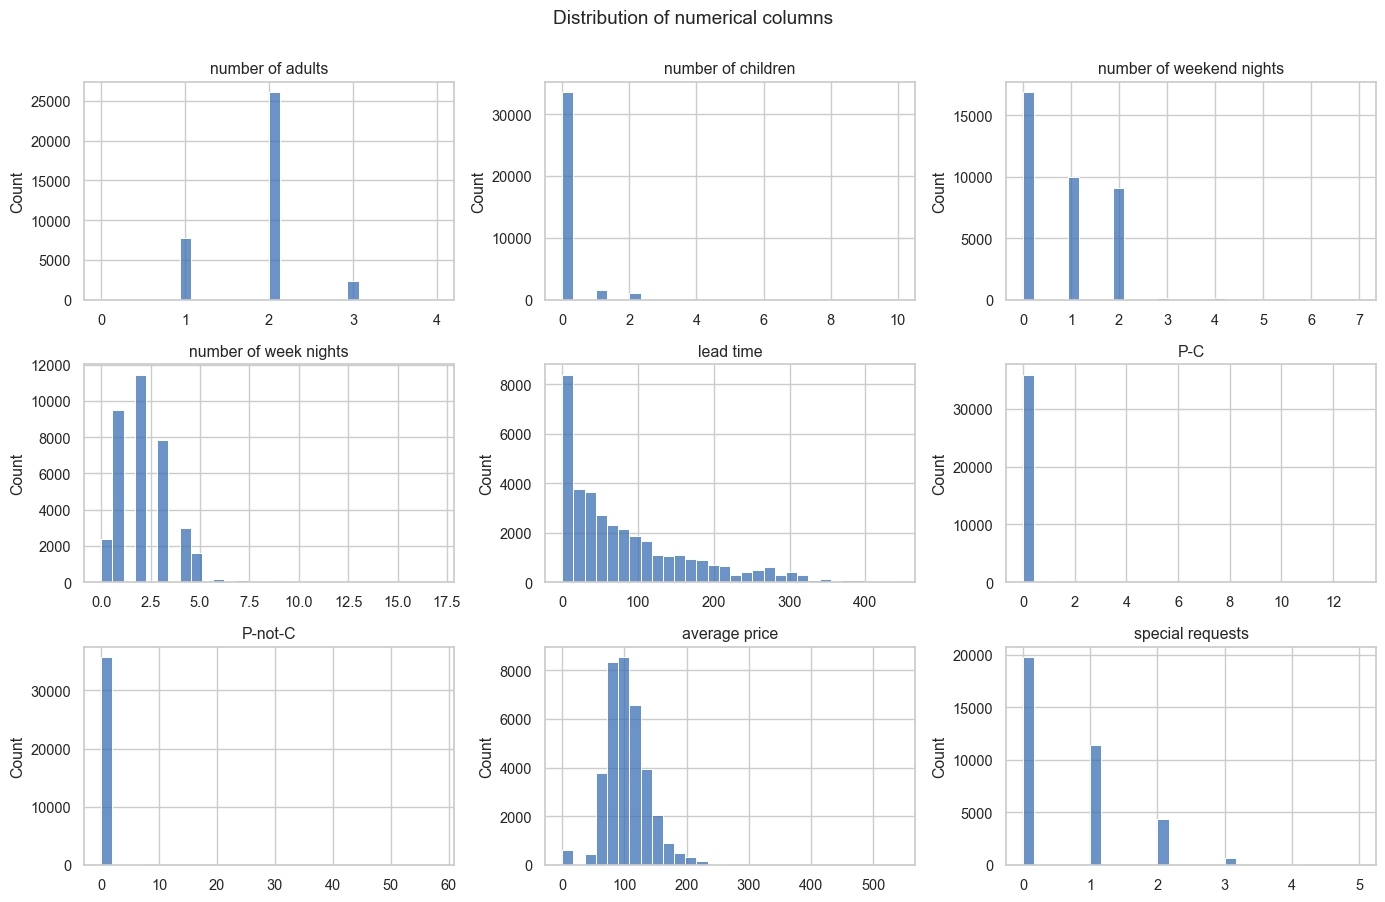

In [7]:
# distribution charts - numerical columns
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for ax, col in zip(axes.ravel(), pp.NUMERIC_COLS):
    sns.histplot(df[col], bins=30, ax=ax, color=C_NOT)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Distribution of numerical columns", y=1.0)
plt.tight_layout()
plt.show()

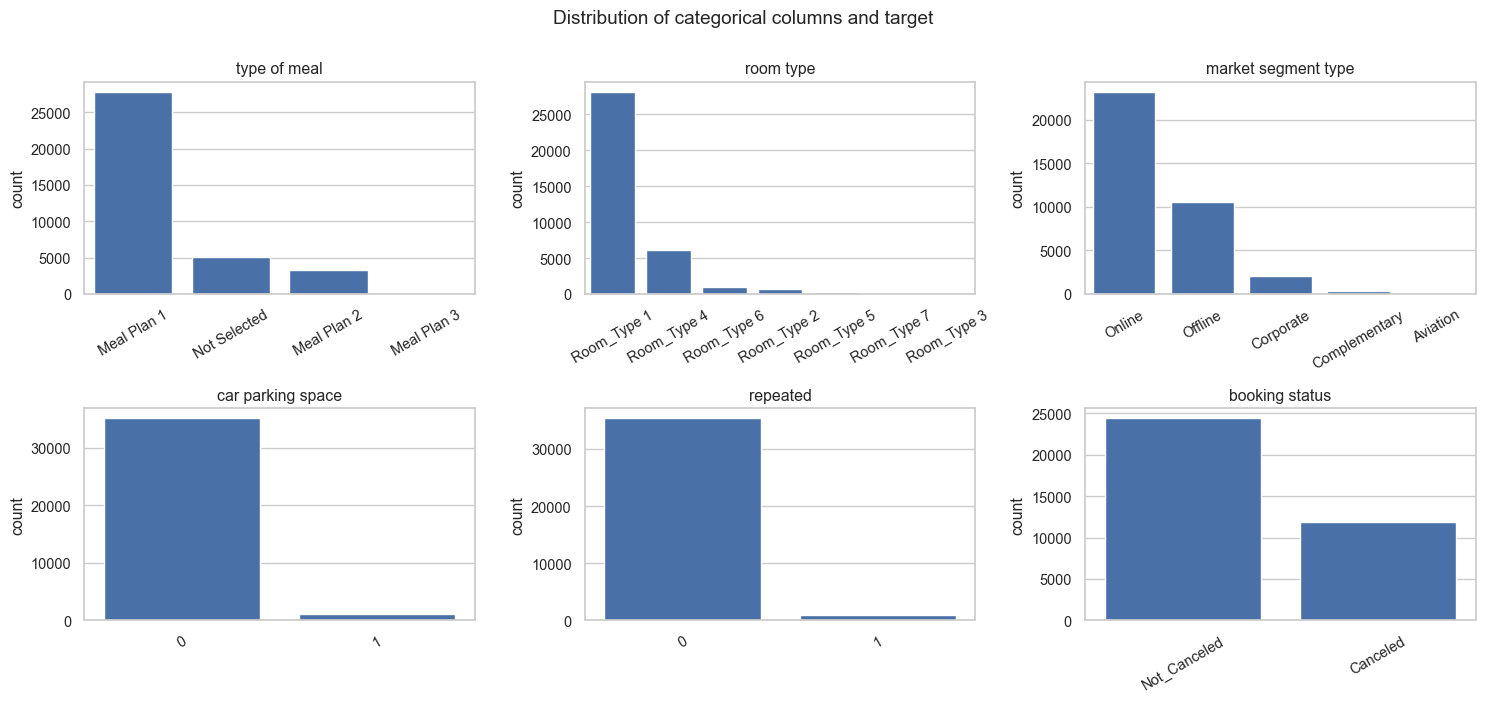

Target balance:
booking status
Not_Canceled    0.672
Canceled        0.328
Name: proportion, dtype: float64


In [8]:
# distribution charts - categorical, binary columns and the target
cat_plot_cols = pp.CATEGORICAL_COLS + pp.BINARY_COLS + [pp.TARGET]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), cat_plot_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, color=C_NOT)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.suptitle("Distribution of categorical columns and target", y=1.0)
plt.tight_layout()
plt.show()

print("Target balance:")
print(df[pp.TARGET].value_counts(normalize=True).round(3))

**Decision:** _Which columns are numerical / categorical / binary? Is the target balanced (see %)? What does the skew in `lead time`, `P-C`, `P-not-C` tell us?_

## 3. Data cleaning and graphs
We keep a log of how many rows each step removes.

In [9]:
cleaning_log = [{"step": "raw data", "rows removed": 0, "rows left": len(df)}]

def log_step(step, df_now):
    left = cleaning_log[-1]["rows left"]
    cleaning_log.append({"step": step, "rows removed": left - len(df_now), "rows left": len(df_now)})

### 3.1 Missing values (blank, NaN)

In [10]:
missing = pd.DataFrame(
    {
        "NaN": df.isna().sum(),
        "blank text": df.apply(lambda c: c.astype(str).str.strip().eq("")).sum(),
    }
)
display(missing.T)

# treat blank text as missing, then drop rows with any missing value
df = df.replace(r"^\s*$", np.nan, regex=True)
df = df.dropna().reset_index(drop=True)
log_step("missing values", df)
print("rows left:", len(df))

,Booking_ID,number of adults,number of children,number of weekend nights,number of week nights,type of meal,car parking space,room type,lead time,market segment type,repeated,P-C,P-not-C,average price,special requests,date of reservation,booking status
NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
blank text,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


rows left: 36285


**Decision:** _Were there missing or blank values? How did we handle them and why?_

### 3.2 Duplicates

In [11]:
print("duplicate Booking_ID:", df[pp.ID_COL].duplicated().sum())

feature_cols = [c for c in df.columns if c != pp.ID_COL]  # compare everything except the ID
dup_mask = df.duplicated(subset=feature_cols, keep="first")
print(f"rows identical to an earlier row (ignoring Booking_ID): {dup_mask.sum()} ({dup_mask.mean():.1%})")

print("Example of identical bookings that only differ by Booking_ID:")
display(df[df.duplicated(subset=feature_cols, keep=False)].sort_values(feature_cols).head(6))

duplicate Booking_ID: 0
rows identical to an earlier row (ignoring Booking_ID): 10276 (28.3%)
Example of identical bookings that only differ by Booking_ID:


,Booking_ID,number of adults,number of children,number of weekend nights,number of week nights,type of meal,car parking space,room type,lead time,market segment type,repeated,P-C,P-not-C,average price,special requests,date of reservation,booking status
2997,INN02998,0,2,0,2,Meal Plan 1,0,Room_Type 2,187,Online,0,0,0,86.5,1,7/7/2018,Canceled
14463,INN14464,0,2,0,2,Meal Plan 1,0,Room_Type 2,187,Online,0,0,0,86.5,1,7/7/2018,Canceled
2694,INN02695,0,2,0,3,Meal Plan 1,0,Room_Type 2,40,Online,0,0,0,6.0,1,1/14/2018,Not_Canceled
22193,INN22194,0,2,0,3,Meal Plan 1,0,Room_Type 2,40,Online,0,0,0,6.0,1,1/14/2018,Not_Canceled
17592,INN17593,0,2,2,1,Meal Plan 1,0,Room_Type 2,104,Online,0,0,0,91.6,2,12/25/2018,Not_Canceled
32816,INN32817,0,2,2,1,Meal Plan 1,0,Room_Type 2,104,Online,0,0,0,91.6,2,12/25/2018,Not_Canceled


In [12]:
DROP_DUPLICATES = True  # set to False to keep them and compare the results

if DROP_DUPLICATES:
    df = df[~dup_mask].reset_index(drop=True)
log_step("duplicate rows", df)
print("rows left:", len(df))

rows left: 26009


**Decision:** _Booking_ID is unique, but many rows are identical in every other column. Why do we remove them? (Hint: the same row can end up in both train and test, which makes the test score look better than it really is.)_

### 3.3 Outliers

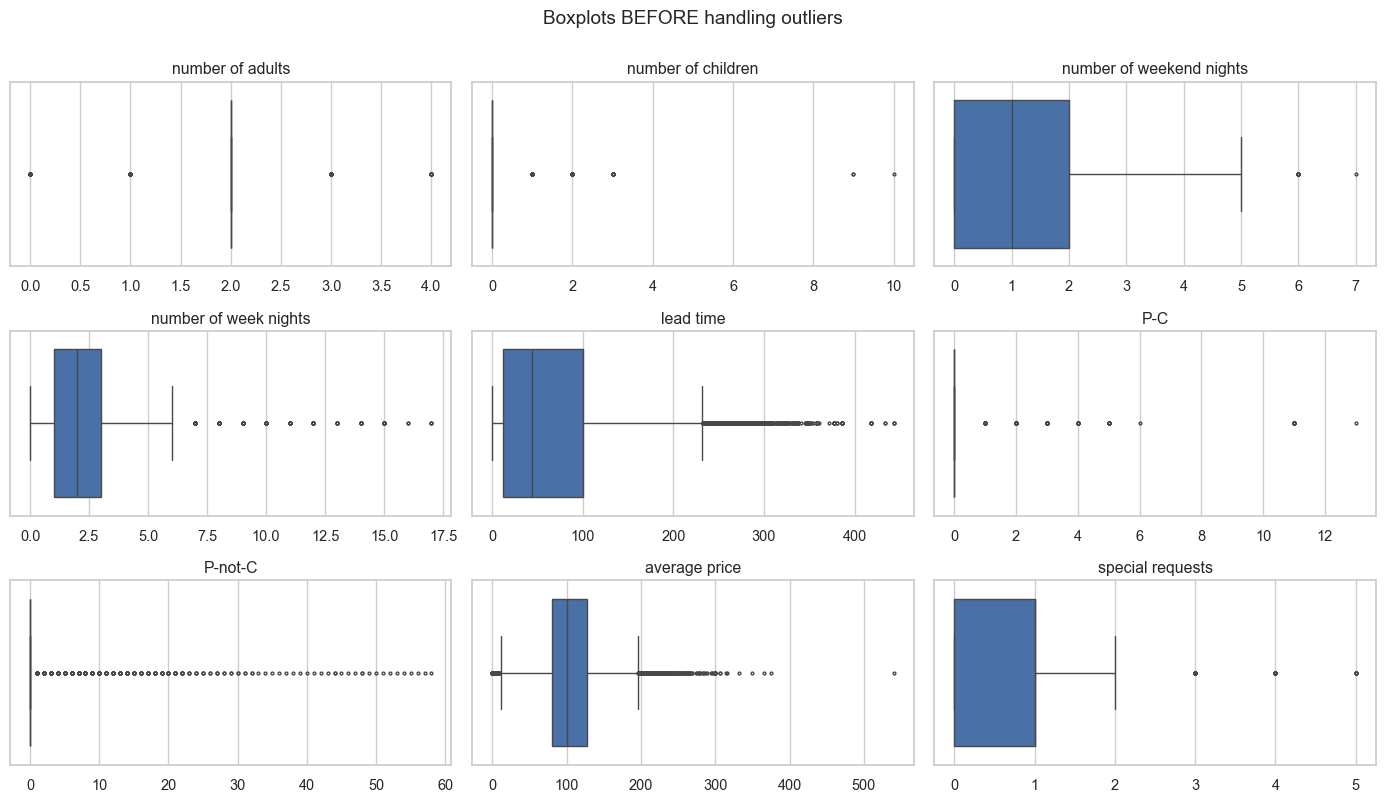

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), pp.NUMERIC_COLS):
    sns.boxplot(x=df[col], ax=ax, color=C_NOT, fliersize=2)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Boxplots BEFORE handling outliers", y=1.0)
plt.tight_layout()
plt.show()

In [14]:
def count_iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())


outlier_table = pd.DataFrame(
    {
        "IQR outliers": df[pp.NUMERIC_COLS].apply(count_iqr_outliers),
        "max value": df[pp.NUMERIC_COLS].max(),
        "99th percentile": df[pp.NUMERIC_COLS].quantile(0.99),
    }
)
outlier_table["% of rows"] = (outlier_table["IQR outliers"] / len(df) * 100).round(1)
outlier_table

,IQR outliers,max value,99th percentile,% of rows
number of adults,7137,4.0,3.00,27.4
number of children,2582,10.0,2.00,9.9
number of weekend nights,21,7.0,3.00,0.1
number of week nights,300,17.0,7.00,1.2
lead time,815,443.0,286.92,3.1
P-C,269,13.0,1.00,1.0
P-not-C,800,58.0,6.00,3.1
average price,1078,540.0,215.00,4.1
special requests,680,5.0,3.00,2.6


,cap value
lead time,287.0
average price,215.0
number of week nights,7.0
number of weekend nights,3.0
number of children,2.0


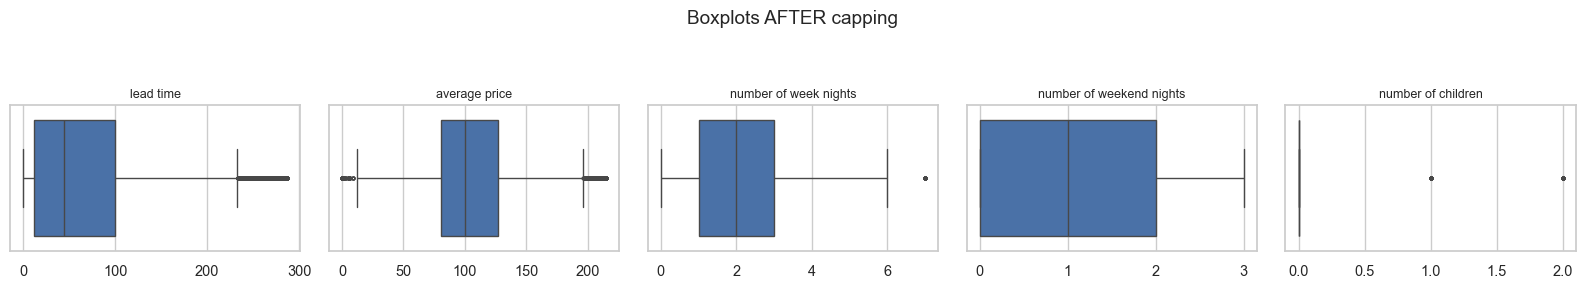

In [15]:
# Handling: cap (winsorize) extreme values at the 99th percentile instead of deleting rows.
# P-C and P-not-C are left alone: they are mostly 0 and a large value is a real loyal customer.
caps = {c: float(np.ceil(df[c].quantile(0.99))) for c in pp.OUTLIER_COLS}
display(pd.Series(caps, name="cap value").to_frame())

df = pp.cap_outliers(df, caps)

fig, axes = plt.subplots(1, len(pp.OUTLIER_COLS), figsize=(16, 2.6))
for ax, col in zip(axes, pp.OUTLIER_COLS):
    sns.boxplot(x=df[col], ax=ax, color=C_NOT, fliersize=2)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
plt.suptitle("Boxplots AFTER capping", y=1.1)
plt.tight_layout()
plt.show()

**Decision:** _Which columns have outliers (boxplots + IQR table)? Why cap at the 99th percentile instead of deleting rows (we keep the row's other information)? Why do we leave `P-C` and `P-not-C` alone?_

_Note: `number of adults` is flagged by the IQR rule (27%) only because almost every booking has exactly 2 adults, which makes the IQR tiny. Values 1-4 are legitimate, so we do not cap it._

### 3.4 Business rules validation
Rules a real booking must follow. Rows that break them are data errors.

In [16]:
nights = df["number of weekend nights"] + df["number of week nights"]
previous_bookings = df["P-C"] + df["P-not-C"]

rules = {
    "at least 1 adult": df["number of adults"] < 1,
    "at least 1 night": nights < 1,
    "price > 0 (free rooms only for Complementary)": (df["average price"] <= 0) & (df["market segment type"] != "Complementary"),
    "repeated guest <=> has previous bookings": (df["repeated"] == 1) != (previous_bookings > 0),
    "no negative lead time or price": (df["lead time"] < 0) | (df["average price"] < 0),
}
display(pd.DataFrame({"rows breaking the rule": {k: int(v.sum()) for k, v in rules.items()}}))

,rows breaking the rule
at least 1 adult,135
at least 1 night,75
price > 0 (free rooms only for Complementary),147
repeated guest <=> has previous bookings,0
no negative lead time or price,0


In [17]:
broken = pd.concat(rules.values(), axis=1).any(axis=1)
df = df[~broken].reset_index(drop=True)
log_step("business rules", df)
print("rows left:", len(df))

rows left: 25717


**Decision:** _Which rules were broken and how many rows? Why remove them instead of fixing them? Why are zero-price Complementary bookings allowed?_

### 3.5 Consistency validation

In [18]:
# text columns: remove stray spaces and list the unique values (spelling variants would show up here)
for col in pp.CATEGORICAL_COLS + [pp.TARGET]:
    df[col] = df[col].str.strip()
    print(f"{col}: {sorted(df[col].unique())}")

print("\nbinary columns only contain 0/1:", bool(df[pp.BINARY_COLS].isin([0, 1]).all().all()))
print("numeric columns really numeric:", all(pd.api.types.is_numeric_dtype(df[c]) for c in pp.NUMERIC_COLS))

type of meal: ['Meal Plan 1', 'Meal Plan 2', 'Meal Plan 3', 'Not Selected']
room type: ['Room_Type 1', 'Room_Type 2', 'Room_Type 3', 'Room_Type 4', 'Room_Type 5', 'Room_Type 6', 'Room_Type 7']
market segment type: ['Aviation', 'Complementary', 'Corporate', 'Offline', 'Online']
booking status: ['Canceled', 'Not_Canceled']

binary columns only contain 0/1: True
numeric columns really numeric: True


In [19]:
# dates: every value must be a real calendar date
parsed = pp.parse_dates(df[pp.DATE_COL])
invalid_dates = parsed.isna()
print("invalid dates:", int(invalid_dates.sum()), "->", df.loc[invalid_dates, pp.DATE_COL].unique()[:5])
print("valid date range:", parsed.min().date(), "to", parsed.max().date())

df = df[~invalid_dates].reset_index(drop=True)
log_step("invalid dates", df)

# target as 0/1
df["canceled"] = (df[pp.TARGET] == "Canceled").astype(int)
print("rows left:", len(df))

invalid dates: 35 -> <ArrowStringArray>
['2018-2-29']
Length: 1, dtype: str
valid date range: 2015-10-02 to 2018-12-31
rows left: 25682


**Decision:** _What inconsistencies did we find (look at the invalid dates)? Why drop those rows?_

In [20]:
# summary of the whole cleaning process + save the cleaned file
cleaning_summary = pd.DataFrame(cleaning_log)
display(cleaning_summary)
print(f"kept {len(df) / len(df_raw):.1%} of the original rows")

df.to_csv(ROOT / "data/processed/booking_clean.csv", index=False)

,step,rows removed,rows left
0,raw data,0,36285
1,missing values,0,36285
2,duplicate rows,10276,26009
3,business rules,292,25717
4,invalid dates,35,25682


kept 70.8% of the original rows


### 3.6 Graphs on the cleaned data

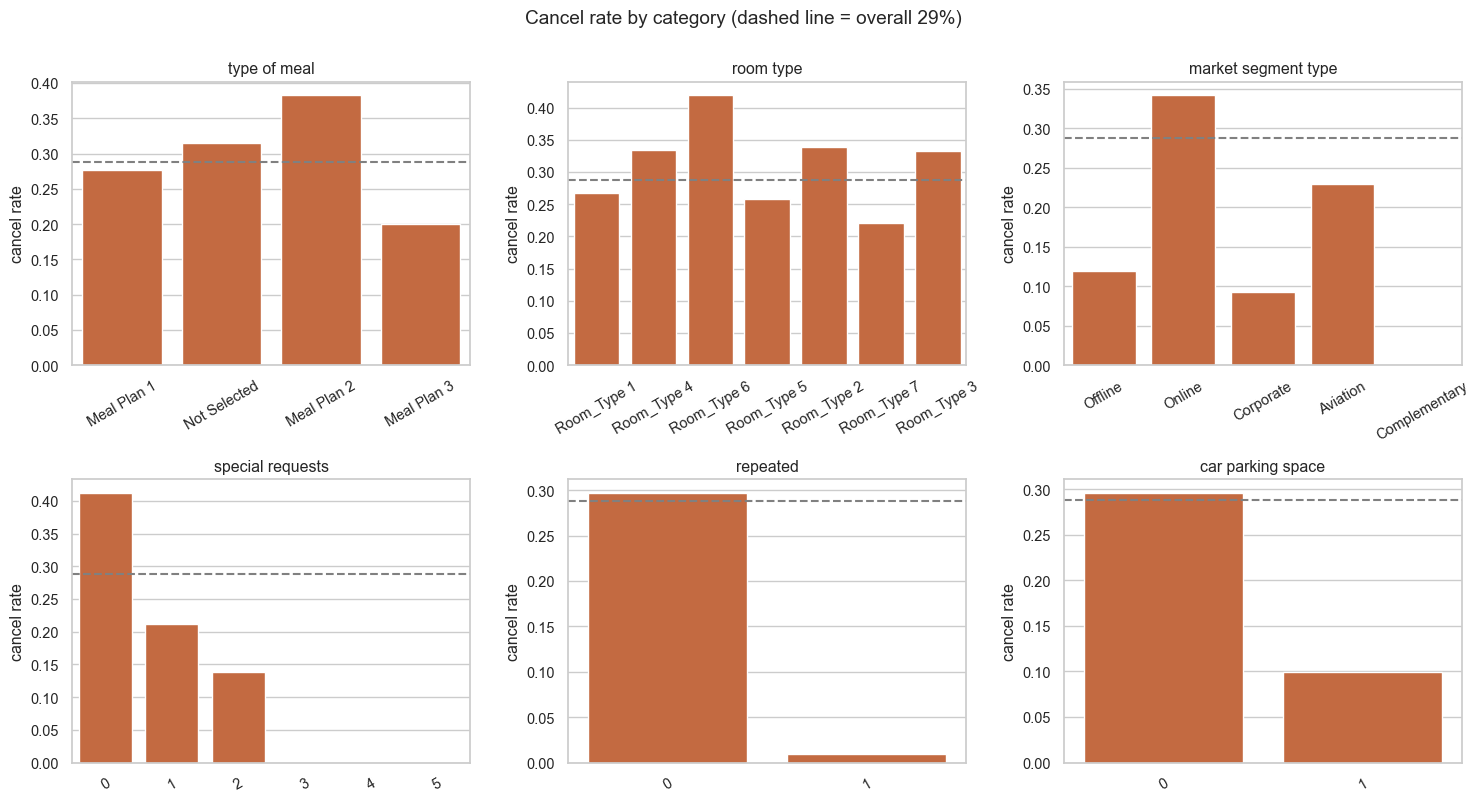

In [21]:
# cancellation rate for each category
cols = pp.CATEGORICAL_COLS + ["special requests", "repeated", "car parking space"]
overall = df["canceled"].mean()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cols):
    sns.barplot(data=df, x=col, y="canceled", errorbar=None, color=C_CAN, ax=ax)
    ax.axhline(overall, ls="--", color="gray")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("cancel rate")
    ax.tick_params(axis="x", rotation=30)
plt.suptitle(f"Cancel rate by category (dashed line = overall {overall:.0%})", y=1.0)
plt.tight_layout()
plt.show()

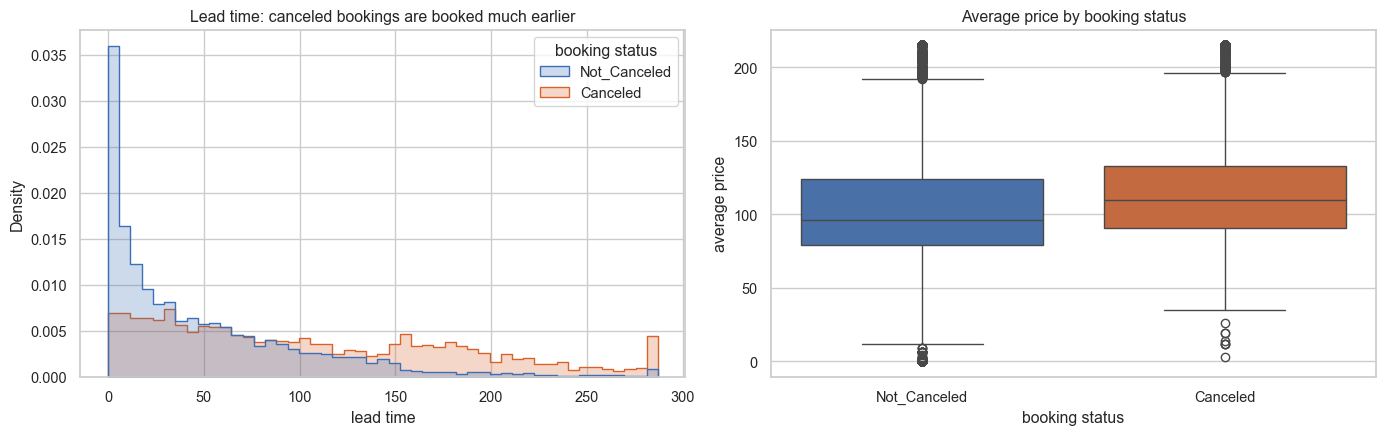

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=df, x="lead time", hue=pp.TARGET, element="step", stat="density",
             common_norm=False, palette=STATUS_PALETTE, ax=axes[0])
axes[0].set_title("Lead time: canceled bookings are booked much earlier")
sns.boxplot(data=df, x=pp.TARGET, y="average price", palette=STATUS_PALETTE, ax=axes[1])
axes[1].set_title("Average price by booking status")
plt.tight_layout()
plt.show()

**Decision:** _Which variables look related to cancellation in these charts (compare each bar with the dashed line)?_

## 4. Feature selection
**Target:** `booking status` (as `canceled` = 0/1). **Dropped before any analysis:** `Booking_ID` (just an identifier) and the raw `date of reservation` text, which we replace by two usable features: the reservation **month** and **weekday**.

,date of reservation,reservation month,reservation weekday
0,10/2/2015,10,4
1,11/6/2018,11,1
2,2/28/2018,2,2
3,5/20/2017,5,5
4,4/11/2018,4,2


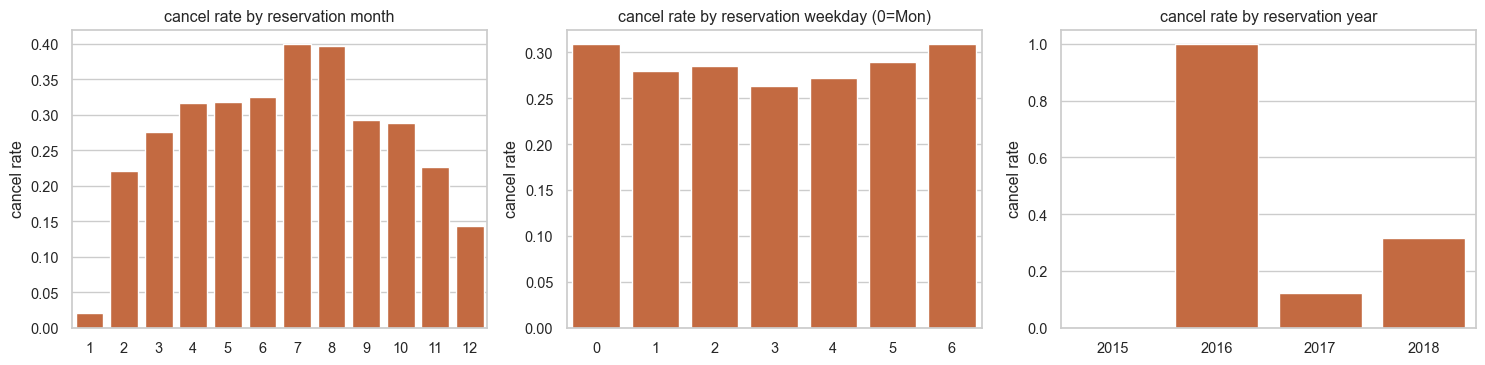

In [23]:
df = pp.add_date_features(df)
display(df[[pp.DATE_COL] + pp.DATE_FEATURES].head())

# does the calendar matter? (year is shown only to explain why we do NOT use it)
year = pp.parse_dates(df[pp.DATE_COL]).dt.year
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (name, values) in zip(axes, [("month", df["reservation month"]), ("weekday (0=Mon)", df["reservation weekday"]), ("year", year)]):
    sns.barplot(x=values, y=df["canceled"], errorbar=None, color=C_CAN, ax=ax)
    ax.set_title(f"cancel rate by reservation {name}")
    ax.set_xlabel("")
    ax.set_ylabel("cancel rate")
plt.tight_layout()
plt.show()

**Decision:** _Month and weekday can be used for future bookings. We do not use the year: the model would depend on years it has never seen and could not generalise to new bookings._

In [24]:
CANDIDATES = pp.CATEGORICAL_COLS + pp.BINARY_COLS + pp.NUMERIC_COLS + pp.DATE_FEATURES
numeric_like = pp.BINARY_COLS + pp.NUMERIC_COLS + pp.DATE_FEATURES
print(len(CANDIDATES), "candidate features")

16 candidate features


### 4.1 Correlation of each feature with the target

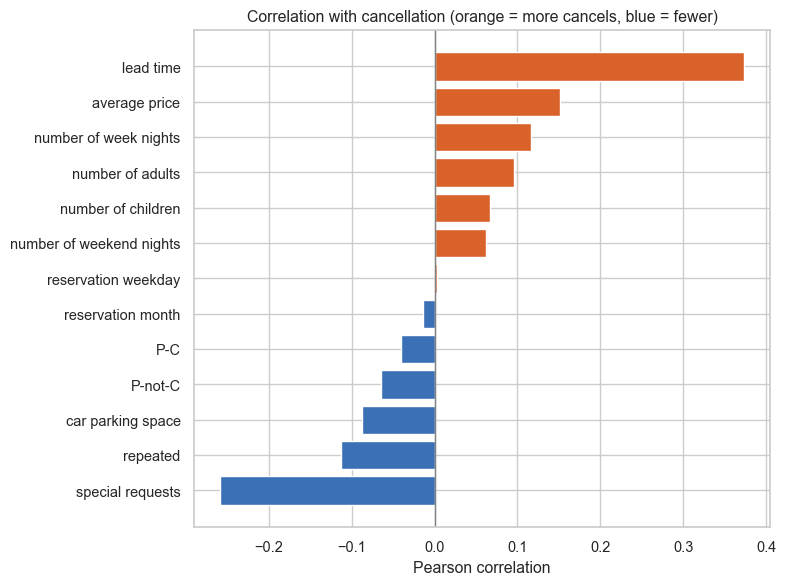

In [25]:
corr_target = df[numeric_like + ["canceled"]].corr()["canceled"].drop("canceled").sort_values()

plt.figure(figsize=(8, 6))
colors = [C_CAN if v > 0 else C_NOT for v in corr_target]
plt.barh(corr_target.index, corr_target.values, color=colors)
plt.axvline(0, color="gray", lw=1)
plt.title("Correlation with cancellation (orange = more cancels, blue = fewer)")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

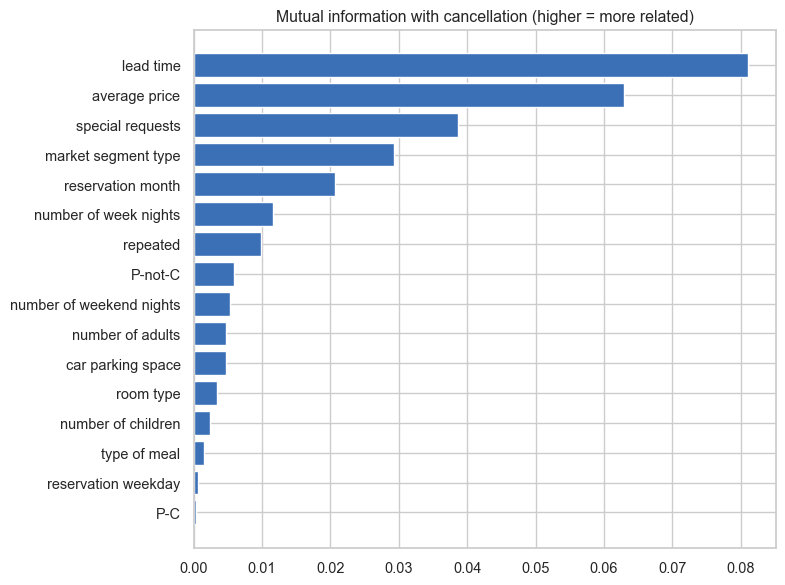

In [26]:
# Pearson cannot be used for text categories, so we also use mutual information (works for any type)
from sklearn.feature_selection import mutual_info_classif

X_enc = df[CANDIDATES].copy()
for col in pp.CATEGORICAL_COLS:
    X_enc[col] = X_enc[col].astype("category").cat.codes

is_discrete = [c in pp.CATEGORICAL_COLS + pp.BINARY_COLS + pp.DATE_FEATURES for c in CANDIDATES]
mutual_info = pd.Series(
    mutual_info_classif(X_enc, df["canceled"], discrete_features=is_discrete, random_state=RANDOM_STATE),
    index=CANDIDATES,
).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(mutual_info.index, mutual_info.values, color=C_NOT)
plt.title("Mutual information with cancellation (higher = more related)")
plt.tight_layout()
plt.show()

### 4.2 Correlation between features (redundancy)

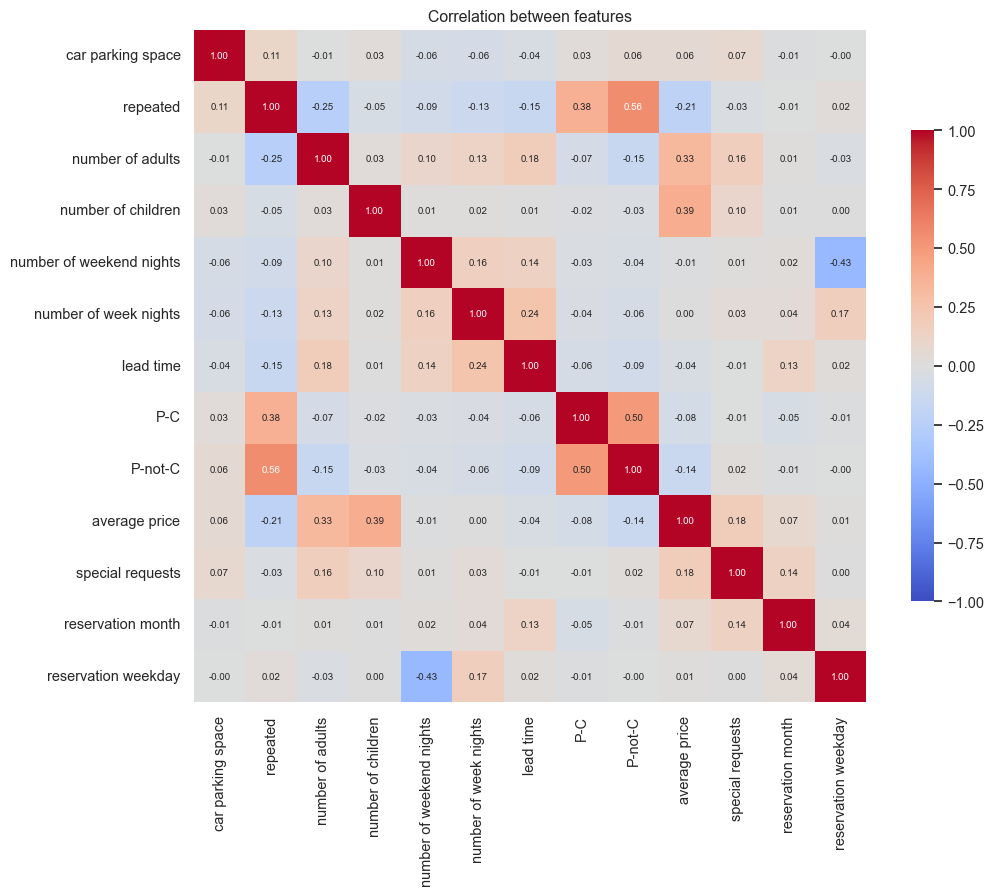

Feature pairs with |correlation| > 0.5 (possible redundancy):


,,correlation
repeated,P-not-C,0.560436


In [27]:
corr_matrix = df[numeric_like].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, annot_kws={"size": 7}, cbar_kws={"shrink": 0.7})
plt.title("Correlation between features")
plt.tight_layout()
plt.show()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)).stack()
redundant_pairs = upper[upper.abs() > 0.5].sort_values(key=abs, ascending=False)
print("Feature pairs with |correlation| > 0.5 (possible redundancy):")
display(redundant_pairs.to_frame("correlation"))

### 4.3 Feature importance (Random Forest)

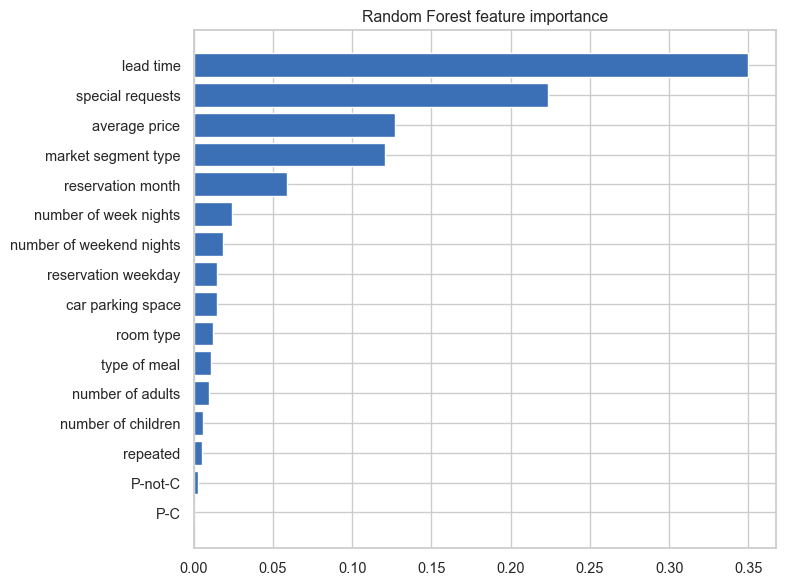

In [28]:
from sklearn.ensemble import RandomForestClassifier

rf_probe = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=3,
                                  random_state=RANDOM_STATE, n_jobs=-1).fit(X_enc, df["canceled"])
importance = pd.Series(rf_probe.feature_importances_, index=CANDIDATES).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(importance.index, importance.values, color=C_NOT)
plt.title("Random Forest feature importance")
plt.tight_layout()
plt.show()

In [29]:
# all evidence in one table
feature_summary = pd.DataFrame(
    {
        "|corr| with target": corr_target.abs(),
        "mutual information": mutual_info,
        "RF importance": importance,
    }
).round(3).sort_values("RF importance", ascending=False)
feature_summary

,|corr| with target,mutual information,RF importance
lead time,0.374,0.081,0.350
special requests,0.259,0.039,0.224
average price,0.152,0.063,0.127
market segment type,NaN,0.029,0.121
reservation month,0.014,0.021,0.059
number of week nights,0.117,0.012,0.024
number of weekend nights,0.062,0.005,0.019
car parking space,0.088,0.005,0.015
reservation weekday,0.003,0.001,0.015
room type,NaN,0.003,0.012


In [30]:
# FINAL FEATURE LIST: drop features that are weak on all three measures and/or redundant
DROPPED_FEATURES = ["P-C", "P-not-C", "repeated", "reservation weekday", "type of meal"]
SELECTED_FEATURES = [c for c in CANDIDATES if c not in DROPPED_FEATURES]
print("selected:", SELECTED_FEATURES)
print("dropped :", DROPPED_FEATURES)

selected: ['room type', 'market segment type', 'car parking space', 'number of adults', 'number of children', 'number of weekend nights', 'number of week nights', 'lead time', 'average price', 'special requests', 'reservation month']
dropped : ['P-C', 'P-not-C', 'repeated', 'reservation weekday', 'type of meal']


In [31]:
# proof that dropping them does not hurt: 5-fold cross-validated ROC-AUC with XGBoost
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier


def cv_auc(features):
    cats = [c for c in features if c in pp.CATEGORICAL_COLS]
    nums = [c for c in features if c not in cats]
    pipe = Pipeline([
        ("prep", ColumnTransformer([("num", StandardScaler(), nums),
                                    ("cat", OneHotEncoder(handle_unknown="ignore"), cats)])),
        ("model", XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                                eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)),
    ])
    return cross_val_score(pipe, df[features], df["canceled"], cv=5, scoring="roc_auc").mean()


print(f"all {len(CANDIDATES)} features      : CV ROC-AUC = {cv_auc(CANDIDATES):.4f}")
print(f"selected {len(SELECTED_FEATURES)} features: CV ROC-AUC = {cv_auc(SELECTED_FEATURES):.4f}")

all 16 features      : CV ROC-AUC = 0.9148
selected 11 features: CV ROC-AUC = 0.9140


**Decision:**

- **Target:** `booking status` (as `canceled` = 0/1).
- **Strongest features:** `lead time`, `special requests`, `average price`, `market segment type`, `reservation month` (top of the table above on all three measures).
- **Dropped `P-C`, `P-not-C`, `repeated`:** weak relation with the target, and `repeated` and `P-not-C` are correlated with each other (redundant, see heatmap).
- **Dropped `reservation weekday` and `type of meal`:** close to zero on correlation, mutual information and importance.
- **Dropped `Booking_ID`:** only an identifier. **Not used `date of reservation`/year:** replaced by month (see 4.0).
- The check above shows the score barely changes with fewer features, so the simpler model is preferred (faster, smaller, easier to send in an API request).

_Confirm the wording against your own table and charts._

## 5. Model selection, training and testing
All 5 models use the same train/test split and the same preprocessing (scale numbers, one-hot encode text), so the comparison is fair.

In [32]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df[SELECTED_FEATURES]
y = df["canceled"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("train:", X_train.shape, " test:", X_test.shape)
print("cancel rate  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

cat_features = [c for c in SELECTED_FEATURES if c in pp.CATEGORICAL_COLS]
num_features = [c for c in SELECTED_FEATURES if c not in cat_features]
prep = ColumnTransformer(
    [
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ]
)

train: (20545, 11)  test: (5137, 11)
cancel rate  train: 0.288  test: 0.288


In [33]:
from catboost import CatBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# settings keep each model small and fast (important for the EC2 file size)
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_leaf=3,
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
    "CatBoost": CatBoostClassifier(iterations=300, depth=6, learning_rate=0.1,
                                   random_seed=RANDOM_STATE, verbose=0),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE),
}

In [34]:
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, roc_auc_score)


def evaluate(name, pipe):
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Train Acc": accuracy_score(y_train, pipe.predict(X_train)),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }


fitted, test_pred, test_proba, rows = {}, {}, {}, []
for name, model in models.items():
    pipe = Pipeline([("prep", clone(prep)), ("model", clone(model))]).fit(X_train, y_train)
    fitted[name] = pipe
    test_pred[name] = pipe.predict(X_test)
    test_proba[name] = pipe.predict_proba(X_test)[:, 1]
    row = evaluate(name, pipe)
    # 5-fold cross-validation on the training set (checks the score is stable, not lucky)
    row["CV F1 (5-fold)"] = cross_val_score(
        Pipeline([("prep", clone(prep)), ("model", clone(model))]), X_train, y_train, cv=5, scoring="f1"
    ).mean()
    rows.append(row)
    print(f"done: {name}")

results = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False).round(4)
results

done: Random Forest
done: XGBoost
done: CatBoost
done: KNN
done: Decision Tree


,Train Acc,Accuracy,Precision,Recall,F1,ROC-AUC,CV F1 (5-fold)
Model,,,,,,,
XGBoost,0.8829,0.8554,0.7842,0.6861,0.7319,0.9138,0.7387
CatBoost,0.8777,0.8554,0.7896,0.6779,0.7295,0.9123,0.7351
Random Forest,0.8741,0.8487,0.7899,0.6461,0.7108,0.9038,0.7217
Decision Tree,0.8539,0.8452,0.7662,0.6651,0.7121,0.8840,0.7148
KNN,0.8438,0.8240,0.7285,0.6191,0.6693,0.8682,0.6663


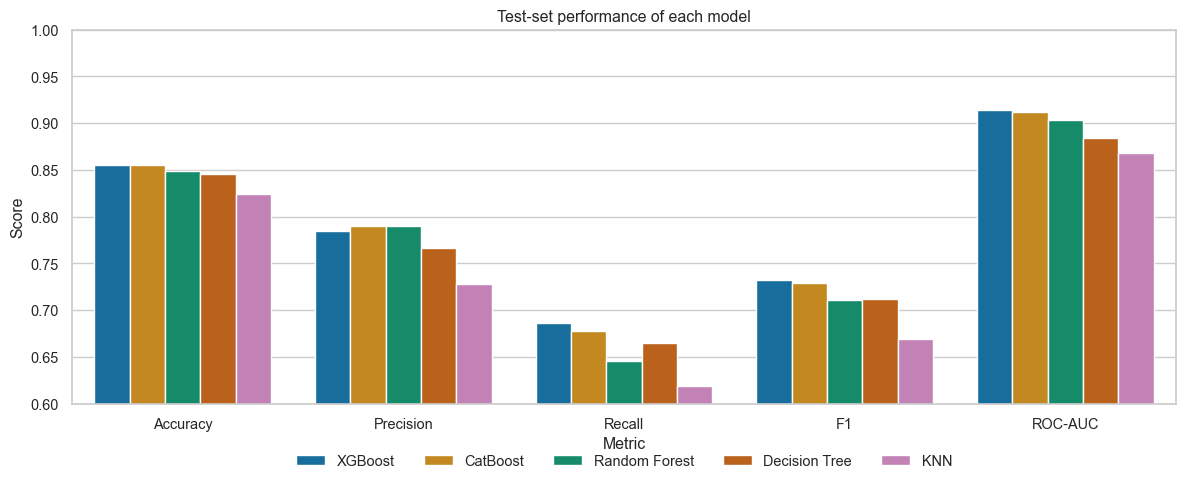

In [35]:
# comparison charts
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
plot_df = results[metrics].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="colorblind")
plt.ylim(0.6, 1.0)
plt.title("Test-set performance of each model")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=5, frameon=False)
plt.tight_layout()
plt.show()

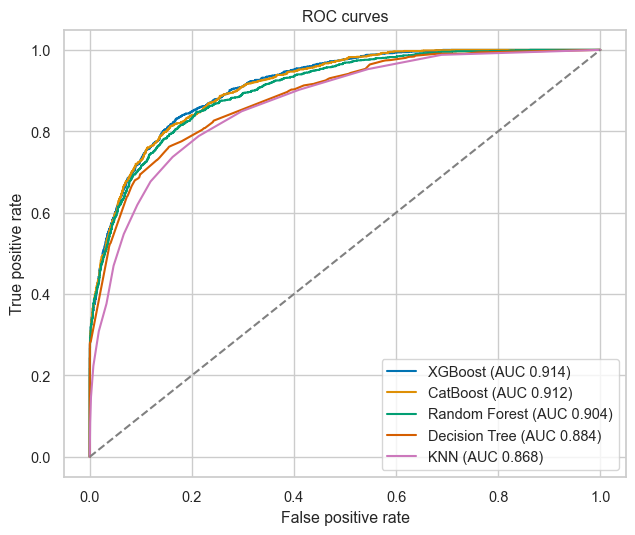

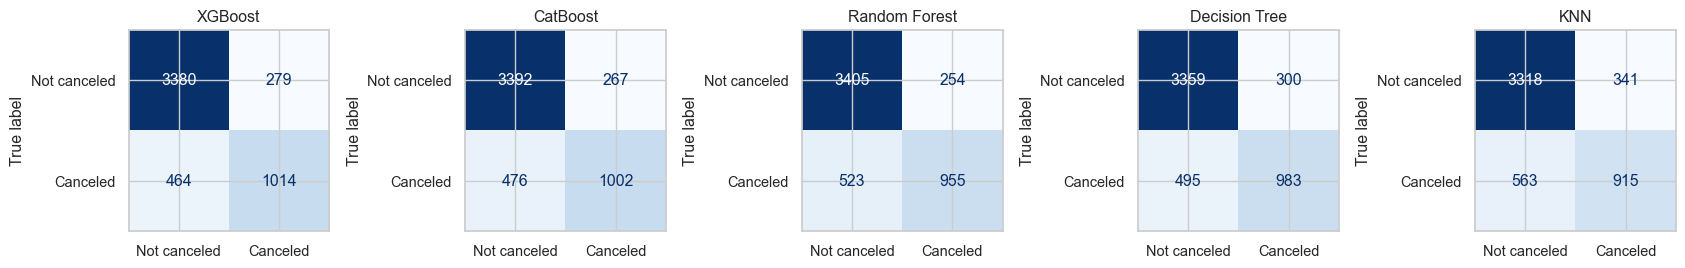

In [36]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve

fig, ax = plt.subplots(figsize=(6.5, 5.5))
palette = sns.color_palette("colorblind", len(models))
for color, name in zip(palette, results.index):
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC {results.loc[name, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="gray")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(models), figsize=(17, 3.6))
for ax, name in zip(axes, results.index):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_pred[name], display_labels=["Not canceled", "Canceled"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [37]:
# the 3 best models (ranked by ROC-AUC) become the base models of the meta-classifier
top3 = results.head(3).index.tolist()
print("Best 3 models:", top3)

Best 3 models: ['XGBoost', 'CatBoost', 'Random Forest']


**Decision:** _Which 3 models are the best and which metric did we rank by (accuracy can mislead because the classes are not balanced, so we also look at F1 and ROC-AUC)? Is any model overfitting (compare `Train Acc` with `Accuracy`)? Why are the weakest models weaker?_

## 6. Meta-classifier (stacking)
How it works:
1. The 3 best models are the **base models**. Each one predicts the probability of cancellation.
2. Those 3 probabilities become the 3 input features of the **meta-classifier** (Logistic Regression), which learns how much to trust each base model.
3. To avoid the meta-classifier trusting models that simply memorised the training data, it is trained on **out-of-fold predictions** (5-fold cross-validation inside `StackingClassifier`).
4. The meta-classifier outputs the final probability; at 0.5 or above the prediction is `Canceled`.

In [38]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

stack = StackingClassifier(
    estimators=[(name, clone(models[name])) for name in top3],
    final_estimator=LogisticRegression(max_iter=1000),
    stack_method="predict_proba",
    cv=5,
)
final_pipe = Pipeline([("prep", clone(prep)), ("stack", stack)]).fit(X_train, y_train)

stack_row = evaluate("Stacking (meta-classifier)", final_pipe)
stack_pred = final_pipe.predict(X_test)
stack_proba = final_pipe.predict_proba(X_test)[:, 1]
print("trained base models:", top3)

trained base models: ['XGBoost', 'CatBoost', 'Random Forest']


In [39]:
# stacking vs every individual model
metric_cols = ["Train Acc", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
comparison = pd.concat([results[metric_cols], pd.DataFrame([stack_row]).set_index("Model")[metric_cols]])
comparison = comparison.round(4).sort_values("ROC-AUC", ascending=False)
comparison

,Train Acc,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Stacking (meta-classifier),0.8809,0.8550,0.7857,0.6820,0.7302,0.9143
XGBoost,0.8829,0.8554,0.7842,0.6861,0.7319,0.9138
CatBoost,0.8777,0.8554,0.7896,0.6779,0.7295,0.9123
Random Forest,0.8741,0.8487,0.7899,0.6461,0.7108,0.9038
Decision Tree,0.8539,0.8452,0.7662,0.6651,0.7121,0.8840
KNN,0.8438,0.8240,0.7285,0.6191,0.6693,0.8682


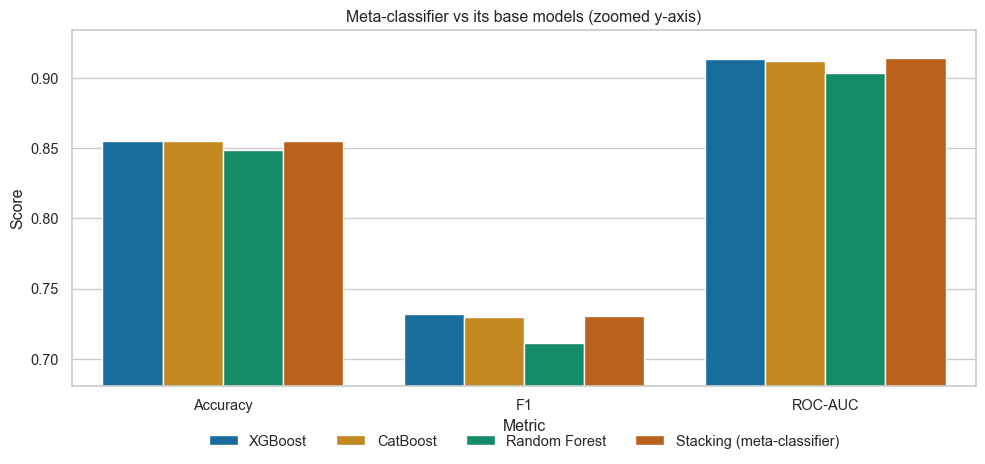

In [40]:
focus = top3 + ["Stacking (meta-classifier)"]
plot_df = comparison.loc[focus, ["Accuracy", "F1", "ROC-AUC"]].reset_index().melt(
    id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(10, 4.8))
ax = sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="colorblind")
low = plot_df["Score"].min()
plt.ylim(max(0, low - 0.03), min(1, plot_df["Score"].max() + 0.02))
plt.title("Meta-classifier vs its base models (zoomed y-axis)")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

In [41]:
# how does the meta-classifier combine the base models?
meta = final_pipe.named_steps["stack"].final_estimator_
weights = pd.Series(meta.coef_[0], index=top3, name="weight")
print("Meta-classifier weights (larger = trusted more):")
display(weights.to_frame())
print("intercept:", round(float(meta.intercept_[0]), 3))

# a few real examples: what each base model said and what the meta-classifier decided
sample = X_test.head(6)
base_probs = final_pipe.named_steps["stack"].transform(final_pipe.named_steps["prep"].transform(sample))
examples = pd.DataFrame(base_probs, columns=[f"{n} P(cancel)" for n in top3], index=sample.index).round(3)
examples["META P(cancel)"] = final_pipe.predict_proba(sample)[:, 1].round(3)
examples["prediction"] = np.where(examples["META P(cancel)"] >= 0.5, "Canceled", "Not_Canceled")
examples["actual"] = np.where(y_test.loc[sample.index] == 1, "Canceled", "Not_Canceled")
examples

Meta-classifier weights (larger = trusted more):


,weight
XGBoost,2.640078
CatBoost,3.232467
Random Forest,0.369998


intercept: -3.098


,XGBoost P(cancel),CatBoost P(cancel),Random Forest P(cancel),META P(cancel),prediction,actual
3352,0.069,0.053,0.111,0.063,Not_Canceled,Not_Canceled
15961,0.142,0.205,0.192,0.120,Not_Canceled,Not_Canceled
7157,0.880,0.866,0.754,0.909,Canceled,Canceled
3415,0.088,0.125,0.100,0.081,Not_Canceled,Not_Canceled
22058,0.052,0.029,0.107,0.056,Not_Canceled,Not_Canceled
3047,0.007,0.005,0.004,0.045,Not_Canceled,Not_Canceled


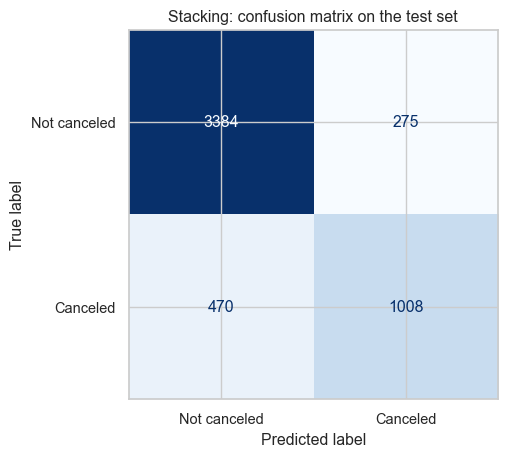

In [42]:
ConfusionMatrixDisplay.from_predictions(
    y_test, stack_pred, display_labels=["Not canceled", "Canceled"], cmap="Blues", colorbar=False
)
plt.title("Stacking: confusion matrix on the test set")
plt.show()

**Decision:** _Did stacking beat the best single model? By how much (see the table)? Which base model does the meta-classifier trust the most (weights)? Is the gain worth the extra complexity?_

## 7. Save the final model
One `joblib` file contains everything needed to predict: preprocessing, the 3 base models and the meta-classifier, plus the outlier caps and feature list. The API loads this single file.

In [43]:
import catboost
import sklearn
import xgboost

artifact = {
    "pipeline": final_pipe,
    "feature_columns": SELECTED_FEATURES,
    "caps": caps,
    "base_models": top3,
    "meta_classifier": "LogisticRegression",
    "metrics": {k: round(float(v), 4) for k, v in stack_row.items() if k != "Model"},
}

MODEL_PATH = ROOT / "models/stacking_model.joblib"
joblib.dump(artifact, MODEL_PATH, compress=3)
print(f"saved {MODEL_PATH.name}: {MODEL_PATH.stat().st_size / 1e6:.1f} MB")

saved stacking_model.joblib: 6.0 MB


In [44]:
# round-trip test: reload the file and predict from RAW booking rows exactly like the API does
loaded = joblib.load(MODEL_PATH)

ids = df.loc[X_test.index[:200], pp.ID_COL]
raw_rows = df_raw.set_index(pp.ID_COL).loc[ids, pp.RAW_INPUT_COLS].reset_index(drop=True)
api_style = pp.predict_from_raw(loaded, raw_rows.to_dict("records"))

api_proba = np.array([r["cancel_probability"] for r in api_style])
notebook_proba = final_pipe.predict_proba(X_test.iloc[:200])[:, 1]
print("max difference between notebook and reloaded model:", np.abs(api_proba - notebook_proba).max())
assert np.abs(api_proba - notebook_proba).max() < 1e-3, "reloaded model disagrees with the notebook!"
print("example output:", api_style[0])

max difference between notebook and reloaded model: 4.9986778676736066e-05
example output: {'prediction': 'Not_Canceled', 'cancel_probability': 0.0628, 'base_model_probabilities': {'XGBoost': 0.0691, 'CatBoost': 0.0531, 'Random Forest': 0.1107}}


In [45]:
# a ready-made request body for Postman
import json

sample_request = json.loads(raw_rows.iloc[[0]].to_json(orient="records"))[0]
(ROOT / "sample_requests/predict.json").write_text(json.dumps(sample_request, indent=2))
print(json.dumps(sample_request, indent=2))

{
  "type of meal": "Meal Plan 1",
  "room type": "Room_Type 1",
  "market segment type": "Online",
  "car parking space": 0,
  "repeated": 0,
  "number of adults": 2,
  "number of children": 0,
  "number of weekend nights": 0,
  "number of week nights": 3,
  "lead time": 77,
  "P-C": 0,
  "P-not-C": 0,
  "average price": 109.93,
  "special requests": 1,
  "date of reservation": "12/31/2017"
}


In [46]:
# pin the library versions used for training: EC2 must install exactly these
requirements = [
    f"pandas=={pd.__version__}",
    f"numpy=={np.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"xgboost=={xgboost.__version__}",
    f"catboost=={catboost.__version__}",
    f"joblib=={joblib.__version__}",
    "fastapi",
    "uvicorn[standard]",
    "pydantic",
]
(ROOT / "requirements.txt").write_text("\n".join(requirements) + "\n")
print("\n".join(requirements))

pandas==3.0.6
numpy==2.5.4
scikit-learn==1.9.1
xgboost==3.2.0
catboost==1.2.10
joblib==1.6.0
fastapi
uvicorn[standard]
pydantic


**Decision:** _What is the final file size and which settings keep it small? Why is everything saved in one file?_

**Next:** deploy `app/` + `src/` + `models/` + `requirements.txt` to EC2 (see README).